# Traffic Accidents in Stavanger - Profiling and Insights

**Bachelor project ADS3 UC3BPR 2026/27**

This notebook profiles police-reported injury accidents in Stavanger municipality (kommune 1103)
to answer three questions from the project proposal:

1. **When** do accidents happen (long-term trend, season, weekday, hour)?
2. **Where and how** do they happen (accident type, location type, roads, speed limit)?
3. **Under which conditions** do they happen, and how do they relate to traffic volume and severity?

| Source | Content | Level |
|---|---|---|
| NVDB API Les v4, object 570/571 | Accident records with conditions, road design and vehicles | One row per accident |
| Trine (Statens vegvesen) | Killed / seriously / lightly injured | Aggregated tables |
| Trafikkdata API | Daily traffic volume per counting station | One row per station and day |

All data: Statens vegvesen, licensed under NLOD 2.0. Input files are produced by
`accident_data_collection.py` and `traffic_volume_analysis.py`.

## 1. Setup

Libraries, paths and a shared plot style. The colours match the traffic-volume notebook so all
figures in the report read as one system: blue is the primary series, orange marks the
highlighted category, and magnitude uses a single-hue blue scale.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

# Paths (the notebook lives in the project root)
PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "figures" / "accidents"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Validated palette shared with traffic_volume_analysis.py
SERIES_BLUE = "#2a78d6"
SERIES_ORANGE = "#eb6834"
SERIES_AQUA = "#1baf7a"
MUTED = "#b9b8b3"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID_COLOUR = "#e4e3df"
SURFACE = "#fcfcfb"
SEQUENTIAL_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#eef5fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)

# Geographic sanity box for Stavanger incl. Finnoy and Rennesoy (removes mis-located points)
LAT_RANGE = (58.80, 59.30)
LON_RANGE = (5.40, 6.20)

# Analysis window for "modern" patterns (road network and traffic comparable to today)
RECENT_FROM_YEAR = 2006


def set_style() -> None:
    """Quiet, report-ready styling shared by every figure."""
    sns.set_theme(style="whitegrid", context="notebook")
    plt.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID_COLOUR,
        "axes.labelcolor": TEXT_SECONDARY,
        "axes.titlecolor": TEXT_PRIMARY,
        "axes.titleweight": "semibold",
        "axes.titlesize": 13,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": GRID_COLOUR,
        "grid.linewidth": 0.8,
        "xtick.color": TEXT_SECONDARY,
        "ytick.color": TEXT_SECONDARY,
        "lines.linewidth": 2,
        "legend.frameon": False,
        "savefig.dpi": 200,
        "savefig.bbox": "tight",
    })


def save(fig: plt.Figure, name: str) -> None:
    """Save a figure as PNG for the report and keep it displayed in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png")


def barh_share(ax: plt.Axes, counts: pd.Series, highlight: str | None = None,
               title: str = "", xlabel: str = "Share of accidents",
               total: float | None = None) -> None:
    """Horizontal bar chart of shares (of `total`, default the sum), largest on top."""
    share = (counts / (total or counts.sum())).sort_values()
    colours = [SERIES_ORANGE if idx == highlight else SERIES_BLUE for idx in share.index]
    ax.barh(share.index, share.values, color=colours, height=0.7)
    for y, value in enumerate(share.values):
        ax.text(value, y, f" {value:.0%}", va="center", fontsize=9, color=TEXT_SECONDARY)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, share.max() * 1.18)
    ax.set(title=title, xlabel=xlabel, ylabel="")
    ax.grid(axis="y", visible=False)


set_style()

## 2. Load and clean the data

The NVDB records use Norwegian category labels. They are translated to English for the report,
`Ukjent` (unknown) is converted to a missing value so it does not appear as a category, and
records with coordinates outside Stavanger are set to missing location (a few records are
geocoded to the wrong place in NVDB).

In [2]:
TRANSLATE = {
    "Ulykkestype": {
        "Kryssende kjøreretning": "Crossing directions",
        "Samme kjøreretning": "Same direction (rear-end etc.)",
        "Fotgjenger/akende": "Pedestrian",
        "Utforkjøring": "Run-off-road",
        "Motsatt kjøreretning": "Head-on / opposite direction",
        "Andre ulykker": "Other (parking etc.)",
    },
    "Føreforhold": {
        "Tørr, bar veg": "Dry",
        "Våt, bar veg": "Wet",
        "Delvis snø / isbelagt veg": "Partly snow / ice",
        "Snø / isbelagt veg": "Snow / ice",
        "Glatt ellers": "Slippery (other)",
    },
    "Lysforhold": {
        "Dagslys": "Daylight",
        "Mørkt med vegbelysning": "Dark, street lit",
        "Tussmørke, skumring": "Twilight",
        "Mørkt uten vegbelysning": "Dark, unlit",
    },
    "Værforhold": {
        "God sikt, opphold": "Good visibility, dry",
        "God sikt, nedbør": "Good visibility, rain",
        "Dårlig sikt, nedbør": "Poor visibility, rain",
        "Dårlig sikt forøvrig": "Poor visibility, other",
        "Dårlig sikt, tåke eller dis": "Poor visibility, fog",
    },
    "Stedsforhold": {
        "Vegstrekning utenfor kryss/avkjørsel": "Road section",
        "3-armet kryss (T-kryss, Y-kryss)": "T/Y-junction",
        "4 armet kryss (X-kryss)": "4-way junction",
        "Rundkjøring": "Roundabout",
        "Avkjørsel": "Driveway / exit",
        "Annet (P-plass, torv, o. l.)": "Parking / square",
        "Annet kryss": "Other junction",
        "Tunnel (primært for motorkjøretøy)": "Tunnel",
        "Bru": "Bridge",
        "Bomstasjon": "Toll station",
        "Undergang (gang- og sykkelveg)": "Underpass",
    },
}
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

raw = pd.read_csv(PROCESSED_DIR / "accidents_enriched.csv", low_memory=False)

acc = raw.copy()
acc["datetime"] = pd.to_datetime(acc["datetime"], errors="coerce")
acc = acc.replace({"Ukjent": np.nan})
for column, mapping in TRANSLATE.items():
    acc[column] = acc[column].map(mapping)

inside = acc["lat"].between(*LAT_RANGE) & acc["lon"].between(*LON_RANGE)
acc.loc[~inside, ["lat", "lon", "station_id", "station_distance_m"]] = np.nan
acc["road"] = acc["road_ref"].str.split().str[0]
acc["decade"] = (acc["year"] // 10 * 10).astype(str) + "s"

recent = acc[acc["year"] >= RECENT_FROM_YEAR].copy()

print(f"Accidents total      : {len(acc):,}  ({acc['year'].min()}-{acc['year'].max()})")
print(f"Accidents {RECENT_FROM_YEAR}+     : {len(recent):,}")
print(f"With valid location  : {acc['lat'].notna().sum():,}")

Accidents total      : 4,630  (1977-2025)
Accidents 2006+     : 1,800
With valid location  : 3,904


### 2.1 Data completeness

Before interpreting any pattern it is important to know how complete each field is. Fields with a
high share of missing values (for example temperature and traffic volume at the site) are only
used for descriptive analysis on the subset where they are known.

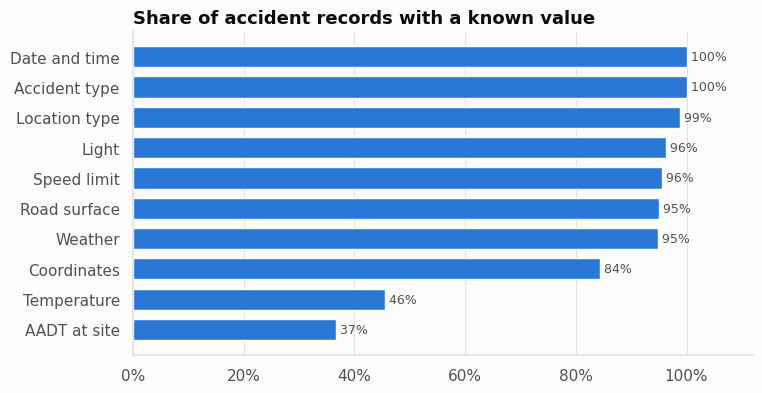

In [3]:
KEY_FIELDS = {
    "datetime": "Date and time",
    "Ulykkestype": "Accident type",
    "Stedsforhold": "Location type",
    "Fartsgrense": "Speed limit",
    "Føreforhold": "Road surface",
    "Lysforhold": "Light",
    "Værforhold": "Weather",
    "lat": "Coordinates",
    "Temperatur": "Temperature",
    "ÅDT": "AADT at site",
}
completeness = pd.Series({label: acc[col].notna().mean() for col, label in KEY_FIELDS.items()})

fig, ax = plt.subplots(figsize=(8, 4.2))
completeness = completeness.sort_values()
ax.barh(completeness.index, completeness.values, color=SERIES_BLUE, height=0.7)
for y, value in enumerate(completeness.values):
    ax.text(value, y, f" {value:.0%}", va="center", fontsize=9, color=TEXT_SECONDARY)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.set(xlim=(0, 1.12), title="Share of accident records with a known value", xlabel="")
ax.grid(axis="y", visible=False)
save(fig, "00_data_completeness")
plt.show()

## 3. When do accidents happen?

### 3.1 Long-term trend

Injury accidents in Stavanger rose until the early 2000s and have fallen steadily since. The
decline is consistent with national road-safety work (Vision Zero, safer vehicles, separated
cycle paths and lower urban speed limits). Whether it also reflects changes in traffic volume is
tested in section 6.

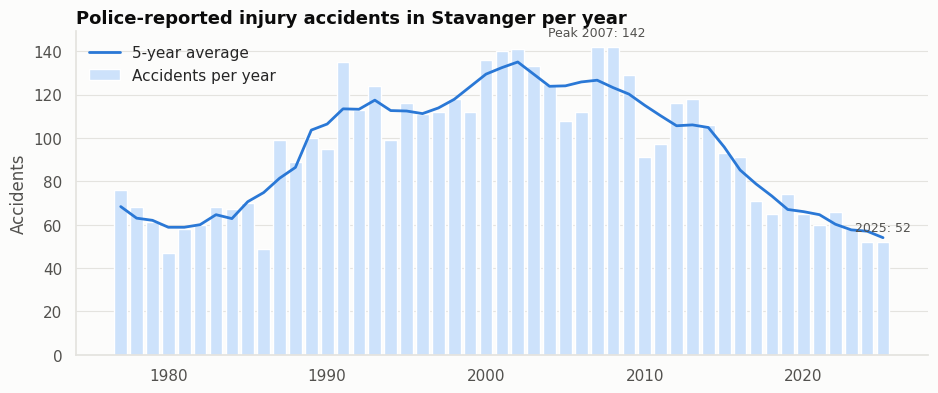

In [4]:
yearly = acc.groupby("year").size()
rolling = yearly.rolling(5, center=True, min_periods=3).mean()

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(yearly.index, yearly.values, color="#cde2fb", width=0.8, label="Accidents per year")
ax.plot(rolling.index, rolling.values, color=SERIES_BLUE, label="5-year average")

peak_year = int(yearly.idxmax())
ax.annotate(f"Peak {peak_year}: {yearly.max()}", xy=(peak_year, yearly.max()),
            xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color=TEXT_SECONDARY)
last_year = int(yearly.index.max())
ax.annotate(f"{last_year}: {yearly.iloc[-1]}", xy=(last_year, yearly.iloc[-1]),
            xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color=TEXT_SECONDARY)

ax.set(title="Police-reported injury accidents in Stavanger per year", xlabel="", ylabel="Accidents")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
save(fig, "01_annual_trend")
plt.show()

### 3.2 Casualties by severity (Trine)

Severity is only available from Trine. The three severity levels differ by two orders of
magnitude, so they are shown as small multiples with independent y-axes rather than on one axis.

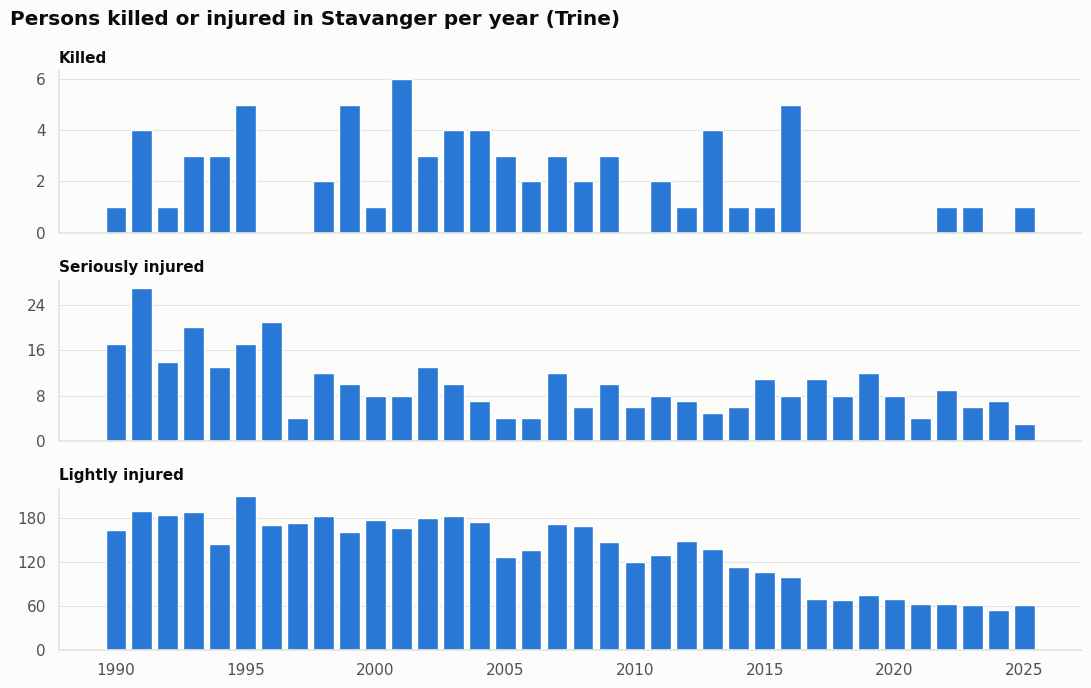

Killed or seriously injured (KSI) 1990-1999: 179 persons
Killed or seriously injured (KSI) 2016-2025: 84 persons
KSI share of all casualties 1990s: 9.2%, last 10 years: 10.9%


In [5]:
trine = pd.read_csv(PROCESSED_DIR / "trine_severity_long.csv")
persons = trine[(trine["unit"] == "persons") & trine["År"].notna()]

casualties = (persons.groupby(["År", "severity"])["count"].sum()
              .unstack().reindex(columns=["killed", "serious", "light"]).fillna(0))
casualties.index = casualties.index.astype(int)

labels = {"killed": "Killed", "serious": "Seriously injured", "light": "Lightly injured"}
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, level in zip(axes, casualties.columns):
    ax.bar(casualties.index, casualties[level], color=SERIES_BLUE, width=0.8)
    ax.set_title(labels[level], fontsize=11)
    ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=4))
    ax.grid(axis="x", visible=False)
fig.suptitle("Persons killed or injured in Stavanger per year (Trine)", x=0.01, ha="left",
             fontweight="semibold", color=TEXT_PRIMARY)
fig.tight_layout()
save(fig, "02_casualties_by_severity")
plt.show()

ksi = casualties["killed"] + casualties["serious"]
ksi_share = ksi / casualties.sum(axis=1)
print(f"Killed or seriously injured (KSI) 1990-1999: {ksi.loc[1990:1999].sum():.0f} persons")
print(f"Killed or seriously injured (KSI) 2016-2025: {ksi.loc[2016:2025].sum():.0f} persons")
print(f"KSI share of all casualties 1990s: {ksi.loc[1990:1999].sum() / casualties.loc[1990:1999].sum().sum():.1%}, "
      f"last 10 years: {ksi.loc[2016:2025].sum() / casualties.loc[2016:2025].sum().sum():.1%}")

### 3.3 Hour of day and weekday

The heatmap uses accidents from 2006 onwards so that the pattern reflects today's road network and
travel habits. Darker cells mean more accidents.

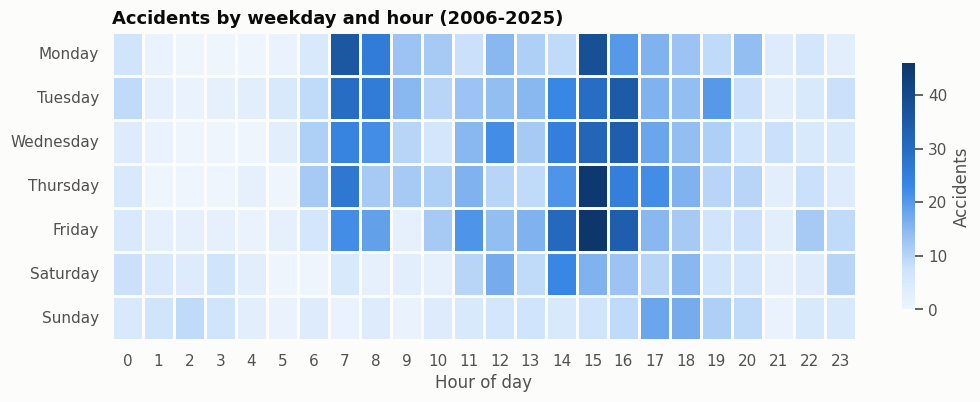

Busiest hour: 15:00 (214 accidents)
Share in afternoon peak 15-18: 28%
Share on weekdays: 81%


In [6]:
timed = recent[recent["time_known"] & recent["hour"].notna()]
heat = (timed.pivot_table(index="weekday", columns="hour", values="nvdb_id", aggfunc="count")
        .reindex(index=WEEKDAYS, columns=range(24)).fillna(0))

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(heat, cmap=SEQUENTIAL_BLUE, linewidths=1, linecolor=SURFACE, ax=ax,
            cbar_kws={"label": "Accidents", "shrink": 0.8})
ax.set(title=f"Accidents by weekday and hour ({RECENT_FROM_YEAR}-{acc['year'].max()})",
       xlabel="Hour of day", ylabel="")
save(fig, "03_weekday_hour_heatmap")
plt.show()

by_hour = timed.groupby("hour").size()
print(f"Busiest hour: {int(by_hour.idxmax()):02d}:00 ({by_hour.max()} accidents)")
print(f"Share in afternoon peak 15-18: {timed['hour'].between(15, 17).mean():.0%}")
print(f"Share on weekdays: {(~timed['is_weekend']).mean():.0%}")

### 3.4 Month and season

Winter months are highlighted to test whether darkness and slippery roads raise the number of
accidents.

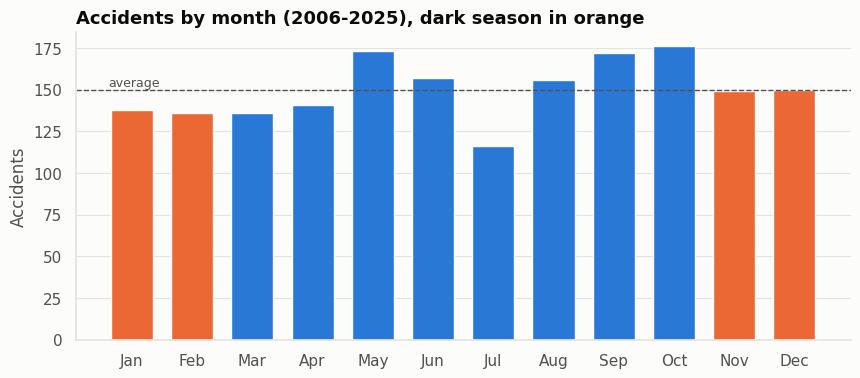

In [7]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly = recent.groupby("month").size().reindex(range(1, 13), fill_value=0)
colours = [SERIES_ORANGE if m in (11, 12, 1, 2) else SERIES_BLUE for m in monthly.index]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(month_names, monthly.values, color=colours, width=0.7)
ax.axhline(monthly.mean(), color=TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.text(-0.4, monthly.mean(), "average", va="bottom", ha="left", fontsize=9, color=TEXT_SECONDARY)
ax.set(title=f"Accidents by month ({RECENT_FROM_YEAR}-{acc['year'].max()}), dark season in orange",
       xlabel="", ylabel="Accidents")
ax.grid(axis="x", visible=False)
save(fig, "04_monthly_pattern")
plt.show()

## 4. How and where do accidents happen?

### 4.1 Accident type and most common accident codes

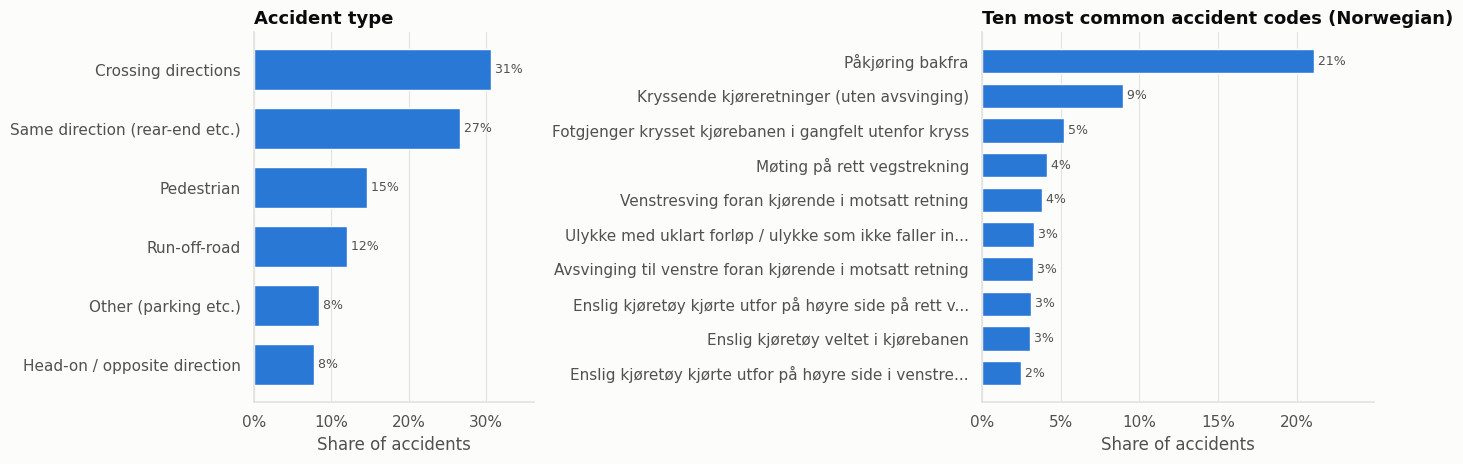

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})

barh_share(axes[0], recent["Ulykkestype"].value_counts(),
           title="Accident type")

top_codes = recent["Ulykkeskode"].value_counts().head(10)
top_codes.index = [label if len(label) <= 55 else label[:52] + "..." for label in top_codes.index]
barh_share(axes[1], top_codes, total=recent["Ulykkeskode"].notna().sum(),
           title="Ten most common accident codes (Norwegian)")
fig.tight_layout()
save(fig, "05_accident_type_and_codes")
plt.show()

### 4.2 Location type

Accidents split between open road sections and junctions. The share printed below the chart adds
all junction types together, which shows how much of the problem is conflicts between turning and
crossing traffic.

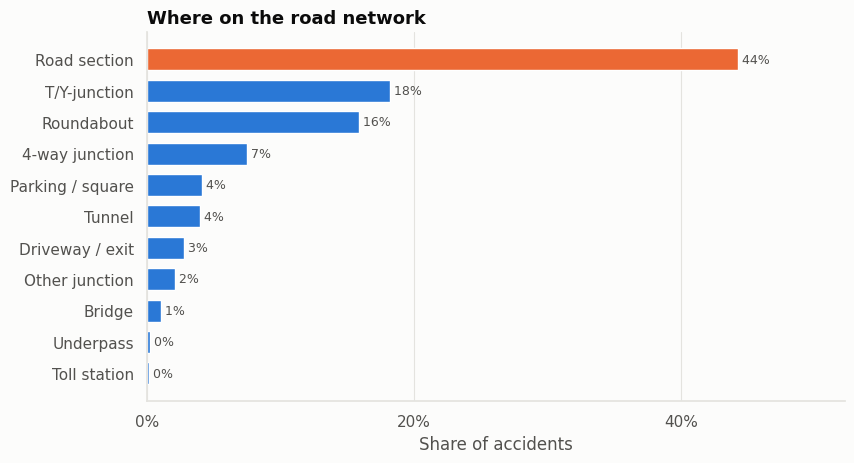

Share in any junction type: 43%


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
location_counts = recent["Stedsforhold"].value_counts()
barh_share(ax, location_counts, highlight="Road section", title="Where on the road network")
save(fig, "06_location_type")
plt.show()

junction_labels = ["T/Y-junction", "4-way junction", "Roundabout", "Other junction"]
print(f"Share in any junction type: {recent['Stedsforhold'].isin(junction_labels).mean():.0%}")

### 4.3 Accident map

Hexagonal binning shows the density of accidents with a known location. Traffic counting
stations from the Trafikkdata API are overlaid as white markers, which shows where accident
locations can be linked to measured traffic volume.

Accidents shown on the urban map: 1,677 of 1,786 located


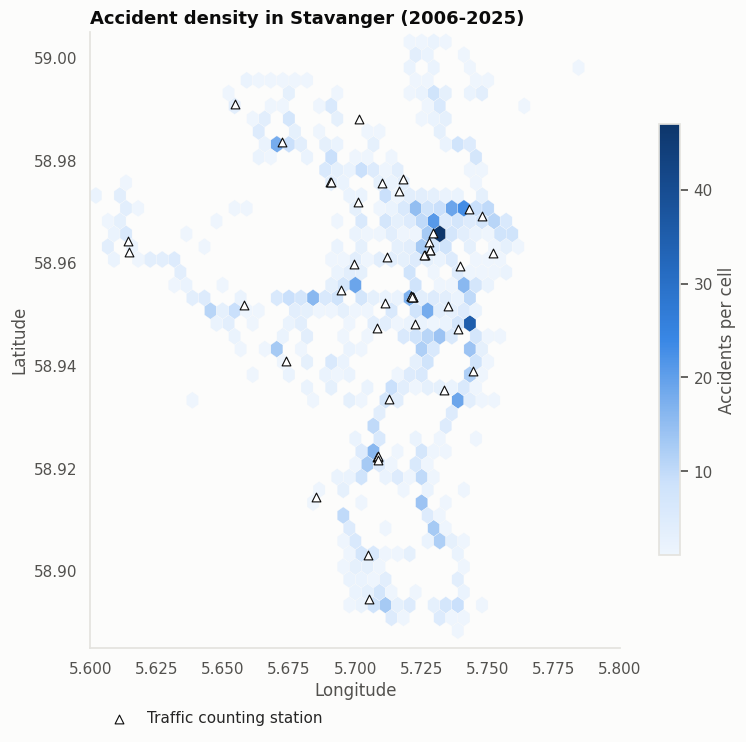

In [10]:
located = recent.dropna(subset=["lat", "lon"])
stations = pd.read_csv(PROCESSED_DIR / "traffic_stations.csv")
stations = stations[stations["lat"].between(*LAT_RANGE) & stations["lon"].between(*LON_RANGE)]

# Focus the map on the urban area (the islands have few accidents and would flatten the view)
lat_lo, lat_hi = 58.885, 59.005
lon_lo, lon_hi = 5.60, 5.80
city = located[located["lat"].between(lat_lo, lat_hi) & located["lon"].between(lon_lo, lon_hi)]
stations = stations[stations["lat"].between(lat_lo, lat_hi) & stations["lon"].between(lon_lo, lon_hi)]
print(f"Accidents shown on the urban map: {len(city):,} of {len(located):,} located")

fig, ax = plt.subplots(figsize=(10, 8))
hb = ax.hexbin(city["lon"], city["lat"], gridsize=40, cmap=SEQUENTIAL_BLUE, mincnt=1,
               linewidths=0.2, edgecolors=SURFACE)
ax.scatter(stations["lon"], stations["lat"], s=40, marker="^", color="white",
           edgecolor=TEXT_PRIMARY, linewidth=0.8, label="Traffic counting station", zorder=3)
ax.set_aspect(1 / np.cos(np.radians(city["lat"].mean())))
ax.set(xlim=(lon_lo, lon_hi), ylim=(lat_lo, lat_hi), xlabel="Longitude", ylabel="Latitude",
       title=f"Accident density in Stavanger ({RECENT_FROM_YEAR}-{acc['year'].max()})")
fig.colorbar(hb, ax=ax, shrink=0.7, label="Accidents per cell")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), frameon=False)
ax.grid(False)
save(fig, "07_accident_density_map")
plt.show()

### 4.4 Roads with the most accidents

The road reference (for example `EV39` for European route 39, `FV` for county roads, `KV` for
municipal roads) identifies which roads carry the largest share of accidents.

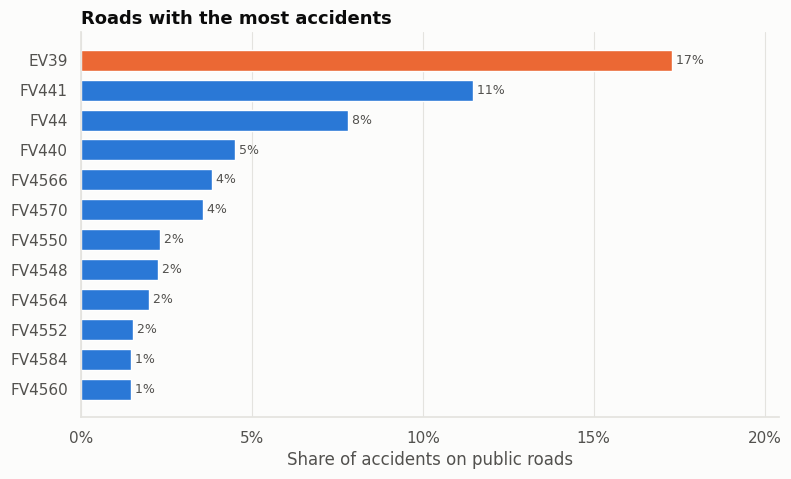

Share by road category: FV: 57%, KV: 22%, EV: 17%, PF: 2%


In [11]:
# PF = private roads; PF99999 is a collective code for unregistered private areas
public_roads = recent["road"].where(~recent["road"].str.startswith("PF", na=False))
top_roads = public_roads.value_counts().head(12)

fig, ax = plt.subplots(figsize=(9, 5))
barh_share(ax, top_roads, total=public_roads.notna().sum(),
           highlight=top_roads.index[0], title="Roads with the most accidents")
ax.set_xlabel("Share of accidents on public roads")
save(fig, "08_top_roads")
plt.show()

category_share = recent["road"].str[:2].value_counts(normalize=True)
print("Share by road category:", ", ".join(f"{k}: {v:.0%}" for k, v in category_share.head(4).items()))

## 5. Under which conditions?

### 5.1 Road surface, light and weather

Unknown values are excluded. These shares describe the conditions at the time of the accident;
without exposure data (how much driving happens in each condition) they show where accidents
concentrate, not the risk per kilometre driven.

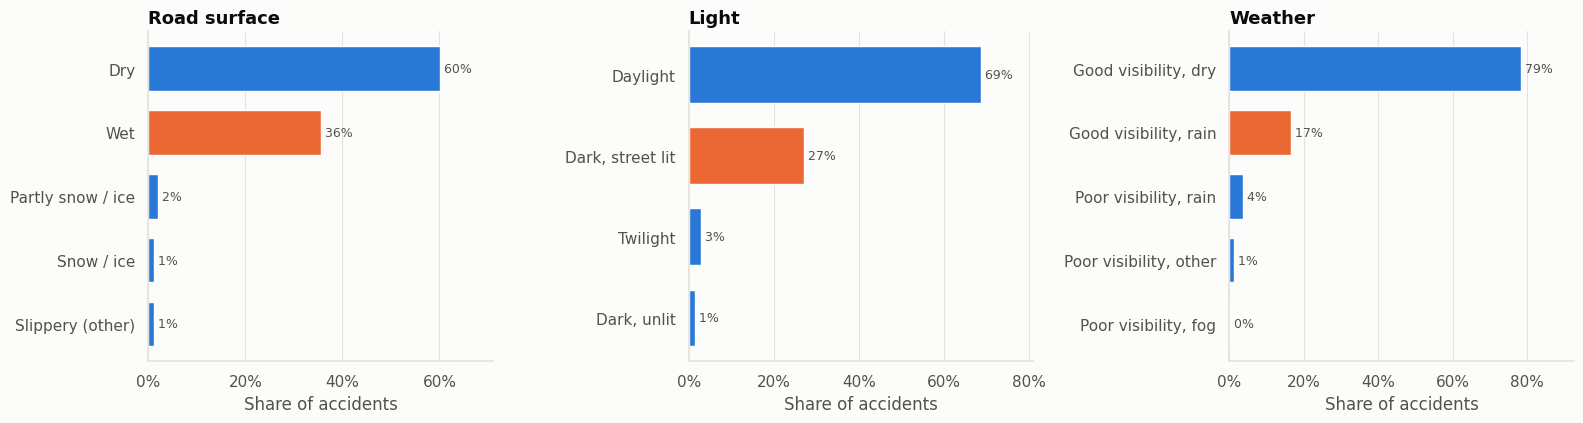

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
barh_share(axes[0], recent["Føreforhold"].value_counts(), highlight="Wet", title="Road surface")
barh_share(axes[1], recent["Lysforhold"].value_counts(), highlight="Dark, street lit", title="Light")
barh_share(axes[2], recent["Værforhold"].value_counts(), highlight="Good visibility, rain", title="Weather")
fig.tight_layout()
save(fig, "09_conditions")
plt.show()

### 5.2 Speed limit and vulnerable road users

Accidents are counted per speed limit, and for each limit the share involving a pedestrian,
cyclist, moped or motorcycle (vulnerable road users, VRU) is shown in a separate panel.

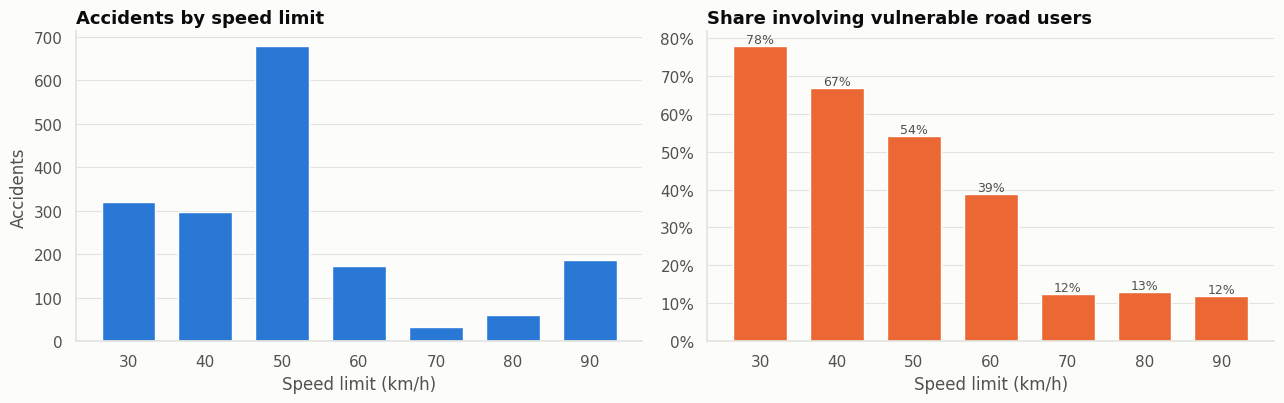

In [13]:
speed = recent.dropna(subset=["Fartsgrense"]).copy()
speed["Fartsgrense"] = speed["Fartsgrense"].astype(int)
speed_counts = speed.groupby("Fartsgrense").size()
vru_share = speed.groupby("Fartsgrense")["involves_vulnerable"].mean()
limits = [str(v) for v in speed_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(limits, speed_counts.values, color=SERIES_BLUE, width=0.7)
axes[0].set(title="Accidents by speed limit", xlabel="Speed limit (km/h)", ylabel="Accidents")

axes[1].bar(limits, vru_share.values, color=SERIES_ORANGE, width=0.7)
for x, value in enumerate(vru_share.values):
    axes[1].text(x, value, f"{value:.0%}", ha="center", va="bottom", fontsize=9, color=TEXT_SECONDARY)
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
axes[1].set(title="Share involving vulnerable road users", xlabel="Speed limit (km/h)", ylabel="")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "10_speed_limit_vru")
plt.show()

### 5.3 Vulnerable road users over time

Share of accidents involving each group of vulnerable road users, per complete five-year period
(the current, incomplete period is left out). A growing cyclist share would support the
proposal's focus on active mobility in the city.

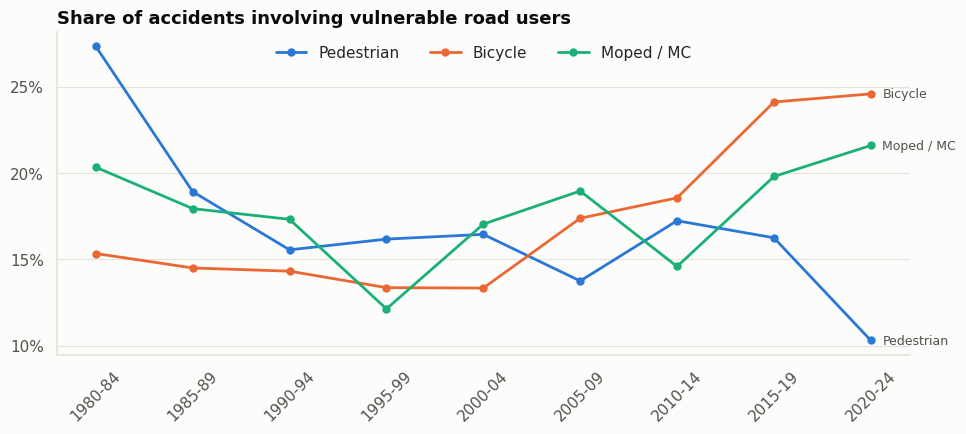

In [14]:
groups = {
    "Pedestrian": "Antall Fotgjengere",
    "Bicycle": "Antall Sykkel",
    "Moped / MC": ["Antall Moped", "Antall MC", "Antall Lett MC"],
}
acc["period"] = (acc["year"] // 5 * 5)
complete_periods = acc.groupby("period")["year"].nunique().loc[lambda n: n == 5].index
trend = pd.DataFrame(index=sorted(complete_periods))
for label, cols in groups.items():
    cols = [cols] if isinstance(cols, str) else cols
    involved = acc[cols].fillna(0).sum(axis=1) > 0
    trend[label] = involved.groupby(acc["period"]).mean().reindex(trend.index)

fig, ax = plt.subplots(figsize=(11, 4.2))
for (label, series), colour in zip(trend.items(), [SERIES_BLUE, SERIES_ORANGE, SERIES_AQUA]):
    ax.plot(series.index, series.values, color=colour, marker="o", markersize=5, label=label)
    ax.text(series.index[-1] + 0.6, series.values[-1], label, va="center", fontsize=9, color=TEXT_SECONDARY)
ax.yaxis.set_major_locator(mticker.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.set_xticks(trend.index, [f"{p}-{str(p + 4)[-2:]}" for p in trend.index], rotation=45)
ax.set(title="Share of accidents involving vulnerable road users", xlabel="", ylabel="")
ax.legend(loc="upper center", ncol=3)
ax.grid(axis="x", visible=False)
save(fig, "11_vru_trend")
plt.show()

## 6. Accidents and traffic volume

Busy roads have more accidents simply because more vehicles pass. To compare locations fairly,
accidents within 500 m of each counting station **and on the same road** (last ten years) are
related to the mean daily traffic at that station. Matching on the road number prevents an
accident on a side street from being counted against a station on a nearby main road or busway.
The accident rate is expressed as accidents per million vehicles passing the station.

Accidents matched to a station on the same road: 150


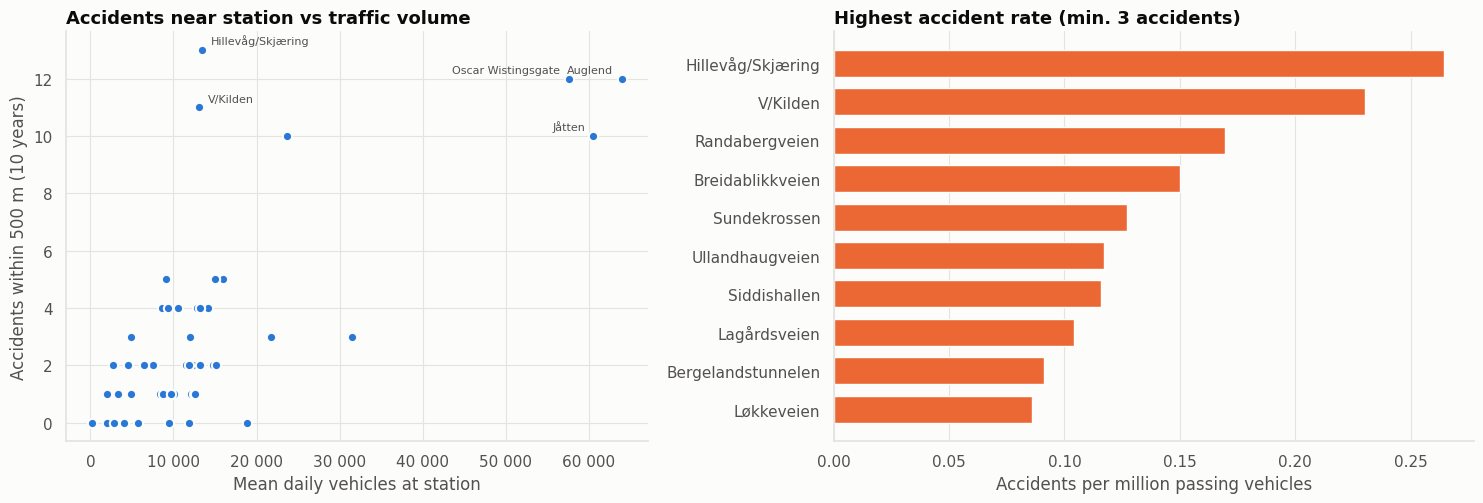

Spearman correlation between station volume and nearby accidents: 0.65


In [15]:
daily = pd.read_csv(PROCESSED_DIR / "traffic_daily.csv")
station_volume = (daily.groupby(["point_id", "name"])["volume"].mean()
                  .rename("mean_daily_volume").reset_index())
station_road = pd.read_csv(PROCESSED_DIR / "traffic_stations.csv")[["point_id", "road_ref"]]
station_road["station_road"] = station_road["road_ref"].str.split().str[0]

last10 = (acc[(acc["year"] > acc["year"].max() - 10) & (acc["station_distance_m"] <= 500)]
          .merge(station_road[["point_id", "station_road"]], left_on="station_id",
                 right_on="point_id", how="left"))
last10 = last10[last10["road"] == last10["station_road"]]
print(f"Accidents matched to a station on the same road: {len(last10):,}")
exposure = (last10.groupby("station_id").size().rename("accidents").reset_index()
            .merge(station_volume, left_on="station_id", right_on="point_id", how="right")
            .fillna({"accidents": 0}))
exposure["vehicles_10y_million"] = exposure["mean_daily_volume"] * 365 * 10 / 1e6
exposure["rate_per_million"] = exposure["accidents"] / exposure["vehicles_10y_million"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})

ax = axes[0]
ax.scatter(exposure["mean_daily_volume"], exposure["accidents"], s=45, color=SERIES_BLUE,
           edgecolor=SURFACE, linewidth=1.5)
for _, row in exposure.nlargest(5, "accidents").iterrows():
    right_side = row["mean_daily_volume"] > exposure["mean_daily_volume"].max() * 0.7
    ax.annotate(row["name"], (row["mean_daily_volume"], row["accidents"]),
                xytext=(-6, 4) if right_side else (6, 4), ha="right" if right_side else "left",
                textcoords="offset points", fontsize=8, color=TEXT_SECONDARY)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.set(title="Accidents near station vs traffic volume", xlabel="Mean daily vehicles at station",
       ylabel="Accidents within 500 m (10 years)")

ranked = exposure[exposure["accidents"] >= 3].nlargest(10, "rate_per_million").sort_values("rate_per_million")
axes[1].barh(ranked["name"], ranked["rate_per_million"], color=SERIES_ORANGE, height=0.7)
axes[1].set(title="Highest accident rate (min. 3 accidents)",
            xlabel="Accidents per million passing vehicles", ylabel="")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "12_accidents_vs_volume")
plt.show()

corr = exposure[["mean_daily_volume", "accidents"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation between station volume and nearby accidents: {corr:.2f}")

## 7. Severity profile (Trine)

KSI = killed or seriously injured. Share of casualties that were KSI by road type, 1990-2025, and the
share of accidents with killed or seriously injured persons by temperature. Categories with fewer
than 30 casualties / accidents are left out because their shares are unstable.

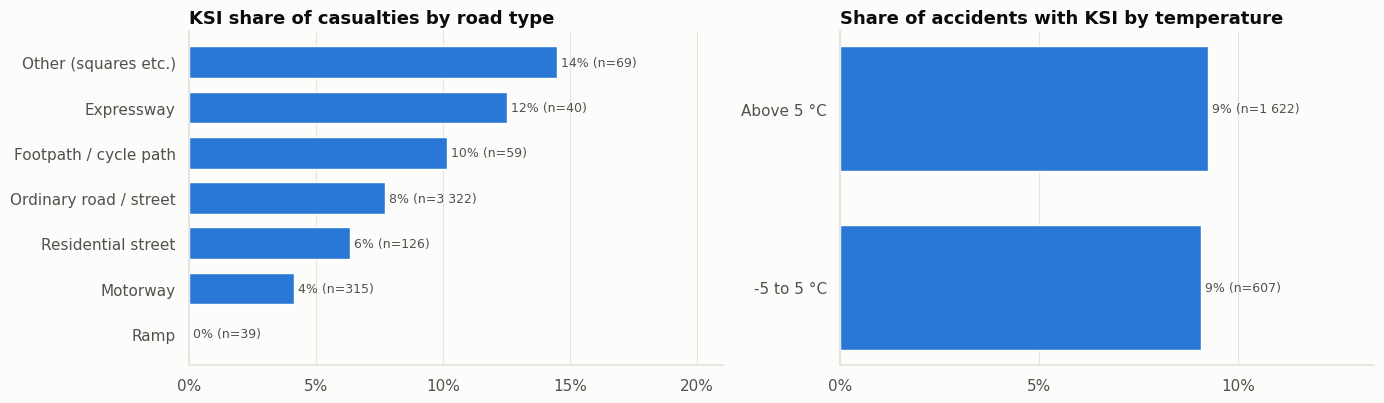

In [16]:
ROAD_TYPE_EN = {
    "Vanlig veg/gate": "Ordinary road / street", "Motorveg": "Motorway",
    "Motortrafikkveg": "Expressway", "Rampe": "Ramp", "Gang-/sykkelveg": "Footpath / cycle path",
    "Gågate/gatetun": "Pedestrian street", "Boliggate, boligveg": "Residential street",
    "Skogsveg": "Forest road", "Annet (plass mm)": "Other (squares etc.)",
}
TEMPERATURE_EN = {
    "Kaldere enn - 5 grader": "Below -5 °C", "-5 t.o.m. 5 grader": "-5 to 5 °C",
    "Varmere enn 5 grader": "Above 5 °C",
}

by_road = (persons.groupby(["dim1_value", "severity"])["count"].sum().unstack(fill_value=0))
by_road["total"] = by_road.sum(axis=1)
by_road = by_road[(by_road["total"] >= 30) & (by_road.index != "Ukjent")]
by_road["ksi_share"] = (by_road["killed"] + by_road["serious"]) / by_road["total"]
by_road.index = by_road.index.map(lambda v: ROAD_TYPE_EN.get(v, v))

temp = trine[(trine["dimensions"] == "Temperatur x Vegdekke")]
by_temp = temp.groupby(["dim1_value", "severity"])["count"].sum().unstack(fill_value=0)
by_temp["total"] = by_temp.sum(axis=1)
by_temp = by_temp[(by_temp["total"] >= 30) & (by_temp.index != "Ukjent")]
by_temp["ksi_share"] = (by_temp["killed"] + by_temp["serious"]) / by_temp["total"]
by_temp.index = by_temp.index.map(lambda v: TEMPERATURE_EN.get(v, v))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, frame, title in [(axes[0], by_road, "KSI share of casualties by road type"),
                         (axes[1], by_temp, "Share of accidents with KSI by temperature")]:
    frame = frame.sort_values("ksi_share")
    ax.barh(frame.index, frame["ksi_share"], color=SERIES_BLUE, height=0.7)
    for y, (value, n) in enumerate(zip(frame["ksi_share"], frame["total"])):
        ax.text(value, y, f" {value:.0%} (n={n:,})".replace(",", " "), va="center",
                fontsize=9, color=TEXT_SECONDARY)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(0.05))
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    ax.set(title=title, xlabel="", ylabel="", xlim=(0, frame["ksi_share"].max() * 1.45))
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "13_severity_profile")
plt.show()

## 8. Key findings

The figures below are computed from the data, so this summary updates automatically when the
data is refreshed.

In [17]:
yearly = acc.groupby("year").size()
peak_decade = acc.groupby("decade").size().idxmax()
change = yearly.loc[2016:2025].mean() / yearly.loc[1996:2005].mean() - 1
junction_share = recent["Stedsforhold"].isin(junction_labels).mean()
top_type = recent["Ulykkestype"].value_counts(normalize=True)
wet_share = recent["Føreforhold"].value_counts(normalize=True).get("Wet", 0)
dark_share = recent["Lysforhold"].isin(["Dark, street lit", "Dark, unlit", "Twilight"]).mean()
weekday_peak = timed.groupby("hour").size().idxmax()
urban_share = speed["Fartsgrense"].le(50).mean()
vru_50 = vru_share.get(50, np.nan)
ksi_change = ksi.loc[2016:2025].sum() / ksi.loc[1996:2005].sum() - 1
top_code = recent["Ulykkeskode"].value_counts(normalize=True)

findings = f"""
1. **Trend.** Accidents peaked in the {peak_decade}; the average for 2016-2025 is **{abs(change):.0%} lower**
   than for 1996-2005. Killed and seriously injured persons changed by **{ksi_change:+.0%}** over the same periods.
2. **Time.** Accidents follow commuting: the busiest hour is **{int(weekday_peak):02d}:00**, and
   **{timed['hour'].between(15, 17).mean():.0%}** occur between 15:00 and 18:00.
3. **Type.** **{top_type.index[0]}** ({top_type.iloc[0]:.0%}) and **{top_type.index[1]}**
   ({top_type.iloc[1]:.0%}) accidents dominate; the single most common code is *{top_code.index[0]}*
   ({top_code.iloc[0]:.0%}).
4. **Location.** **{junction_share:.0%}** of accidents happen in junctions or roundabouts, and
   **{urban_share:.0%}** on roads with a speed limit of 50 km/h or lower.
5. **Conditions.** **{wet_share:.0%}** happen on wet roads and **{dark_share:.0%}** in darkness or twilight,
   both relevant in Stavanger's climate.
6. **Vulnerable road users.** At 50 km/h, **{vru_50:.0%}** of accidents involve a pedestrian, cyclist,
   moped or motorcycle.
7. **Exposure.** Station volume and nearby accidents have a Spearman correlation of **{corr:.2f}**:
   volume explains part of the pattern, and locations with a high rate per vehicle are candidates for
   closer study.
"""
display(Markdown(findings))


1. **Trend.** Accidents peaked in the 2000s; the average for 2016-2025 is **47% lower**
   than for 1996-2005. Killed and seriously injured persons changed by **-33%** over the same periods.
2. **Time.** Accidents follow commuting: the busiest hour is **15:00**, and
   **28%** occur between 15:00 and 18:00.
3. **Type.** **Crossing directions** (31%) and **Same direction (rear-end etc.)**
   (27%) accidents dominate; the single most common code is *Påkjøring bakfra*
   (21%).
4. **Location.** **43%** of accidents happen in junctions or roundabouts, and
   **74%** on roads with a speed limit of 50 km/h or lower.
5. **Conditions.** **36%** happen on wet roads and **30%** in darkness or twilight,
   both relevant in Stavanger's climate.
6. **Vulnerable road users.** At 50 km/h, **54%** of accidents involve a pedestrian, cyclist,
   moped or motorcycle.
7. **Exposure.** Station volume and nearby accidents have a Spearman correlation of **0.65**:
   volume explains part of the pattern, and locations with a high rate per vehicle are candidates for
   closer study.


## 9. Next step: machine learning

The profiling above suggests the features for the modelling notebook:

| Question | Model | Target | Main features |
|---|---|---|---|
| Which factors are linked to vulnerable road users being hit? | Gradient boosting classifier + SHAP / permutation importance | `involves_vulnerable` | Speed limit, location type, light, surface, hour, weekday, road category |
| Where are the hotspots? | DBSCAN / HDBSCAN on coordinates | Cluster label | Latitude, longitude (last 10 years) |
| How many accidents to expect per road / month? | Poisson or negative binomial regression | Accident count | Traffic volume, speed limit, season |

Severity at record level is not public in NVDB, so severity is analysed through the Trine tables
rather than as a model target.